# EDA – Dự đoán khách hàng đăng ký tiền gửi có kỳ hạn (Bank Marketing)

## Bài toán
Ngân hàng gọi điện bán tiền gửi có kỳ hạn nhưng chỉ khoảng **12%** khách đồng ý; gọi đại trà tốn chi phí. Mục tiêu của dự án: **dự đoán khách nào có khả năng đồng ý trước khi gọi** để tập trung nguồn lực đúng chỗ. Nhãn `y = 1` nếu khách đồng ý.

## Mục tiêu của EDA
Trả lời: (1) dữ liệu có đáng tin không, (2) khách nào dễ đồng ý, (3) gọi như thế nào, (4) có cảnh báo gì cho bước mô hình.

## 1. Từ điển dữ liệu

| Nhóm | Biến | Kiểu | Ý nghĩa | Biết trước cuộc gọi? |
|---|---|---|---|---|
| Hồ sơ khách | `age` | Số | Tuổi | Có |
| | `job`, `marital`, `education` | Phân loại | Nghề, hôn nhân, học vấn | Có |
| Tài chính | `balance` | Số | Số dư trung bình năm (EUR) | Có |
| | `default`, `housing`, `loan` | Nhị phân | Nợ xấu, vay nhà, vay cá nhân | Có |
| Lịch sử chiến dịch | `pdays` | Số | Số ngày từ lần liên hệ trước (-1 = chưa từng) | Có |
| | `previous` | Số | Số lần liên hệ trước chiến dịch này | Có |
| | `poutcome` | Phân loại | Kết quả chiến dịch trước | Có |
| Cách tiếp cận | `contact` | Phân loại | Loại liên hệ (di động, cố định, không rõ) | Có |
| | `month`, `day` | Phân loại, số | Tháng, ngày liên hệ gần nhất | Có (`day` ít ý nghĩa) |
| | `campaign` | Số | Số lần gọi trong chiến dịch, **gồm cả cuộc gọi cuối** | **Leak nhẹ** |
| Kết quả cuộc gọi | `duration` | Số | Thời lượng cuộc gọi (giây) | **Không** (chỉ biết sau khi gọi) |
| Nhãn | `y` | Nhị phân | Có đăng ký tiền gửi không | Biến mục tiêu |

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, warnings
from sklearn.metrics import roc_auc_score
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 11})

raw = pd.read_csv('bank-full.csv', sep=';')       # dữ liệu gốc, chưa chỉnh sửa
raw.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 2. Kiểm tra chất lượng dữ liệu

In [2]:
print('Kích thước:', raw.shape, '| Ô thiếu (NaN):', int(raw.isna().sum().sum()), '| Dòng trùng:', int(raw.duplicated().sum()))
print(raw.dtypes.value_counts().to_dict())

# Giá trị 0 hoặc mã đặc biệt
print('\nGiá trị 0 / mã đặc biệt:')
print({'balance = 0': int((raw['balance'] == 0).sum()), 'previous = 0': int((raw['previous'] == 0).sum()),
       'pdays = -1': int((raw['pdays'] == -1).sum()), 'duration <= 0': int((raw['duration'] <= 0).sum())})

# Giá trị 'unknown' theo cột
unk = pd.DataFrame({'Số dòng unknown': {c: int((raw[c] == 'unknown').sum()) for c in raw.select_dtypes('object')}})
unk['% dòng'] = (unk['Số dòng unknown'] / len(raw) * 100).round(2)
unk[unk['Số dòng unknown'] > 0]

Kích thước: (45211, 17) | Ô thiếu (NaN): 0 | Dòng trùng: 0
{<StringDtype(na_value=nan)>: 10, dtype('int64'): 7}

Giá trị 0 / mã đặc biệt:
{'balance = 0': 3514, 'previous = 0': 36954, 'pdays = -1': 36954, 'duration <= 0': 3}


,Số dòng unknown,% dòng
job,288,0.64
education,1857,4.11
contact,13020,28.80
poutcome,36959,81.75


**Đọc kết quả:** dữ liệu **không có ô thiếu (NaN) và không có dòng trùng**. Vấn đề nằm ở các **giá trị đặc biệt**, và mỗi loại cần một cách xử lý có lý do:

| Phát hiện | Số lượng | Cách xử lý | Lý do |
|---|---|---|---|
| `poutcome = unknown` | 36,959 (81.8%) | 36,951 dòng thuộc nhóm **chưa từng liên hệ** → đổi thành `nonexistent`; 5 dòng còn lại giữ `unknown` | Không phải "thiếu thông tin" mà là "chưa có chiến dịch trước". Bỏ đi sẽ mất 82% dữ liệu |
| `contact = unknown` | 13,020 (28.8%) | **Giữ làm nhóm riêng** | Có tín hiệu thật: chỉ 4.1% đồng ý (mục 5) |
| `education = unknown` | 1,857 (4.1%) | Giữ làm nhóm riêng trong EDA | Điền thiếu là bước "học thống kê", để trong Pipeline ở bước mô hình |
| `job = unknown` | 288 (0.6%) | Giữ làm nhóm riêng trong EDA | Như trên |
| `balance = 0` | 3,514 | **Giữ** | Tài khoản trống là quan sát hợp lệ |
| `previous = 0`, `pdays = -1` | 36,954 | **Giữ** (`pdays = -1` là mã "chưa từng liên hệ") | Hợp lệ, mang ý nghĩa nghiệp vụ |
| `duration ≤ 0` | **3 dòng** | **Loại bỏ** | Cuộc gọi không thể có thời lượng ≤ 0: dòng lỗi |

In [3]:
# Làm sạch THEO TỪNG DÒNG (quy tắc cố định, không học thống kê nào từ dữ liệu)
df = raw[raw['duration'] > 0].reset_index(drop=True)                 # loại 3 dòng lỗi
df['y'] = df['y'].map({'yes': 1, 'no': 0})
never = (df['previous'] == 0) & (df['pdays'] == -1)                   # chưa từng được liên hệ
df.loc[never & (df['poutcome'] == 'unknown'), 'poutcome'] = 'nonexistent'
print(f'{len(raw):,} -> {len(df):,} dòng | poutcome còn unknown: {(df["poutcome"] == "unknown").sum()}')

# Suy ra giai đoạn (file xếp theo thời gian, không có cột năm): mỗi lần tháng quay về 'jan' là sang năm mới
MONTHS = ['jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec']
m = df['month'].map({k: i for i, k in enumerate(MONTHS)})
df['period'] = (m.diff().fillna(0) < 0).cumsum().map({0: '2008', 1: '2009', 2: '2010'})
BASE = df['y'].mean() * 100
print(f'Tỉ lệ Yes nền: {BASE:.1f}%')

# Hai hàm vẽ dùng chung: tỉ lệ Yes theo nhóm (xanh = trên nền, đỏ = dưới nền)
def rate_table(key, data=None):
    g = (df if data is None else data).groupby(key, observed=True)['y'].agg(n='size', rate='mean')
    g['rate'] *= 100
    return g

def plot_rate(ax, g, title, horizontal=False):
    colors = ['#2ecc71' if r >= BASE else '#e74c3c' for r in g['rate']]
    labels, pad = g.index.astype(str), g['rate'].max() * 0.02
    if horizontal:
        ax.barh(labels, g['rate'], color=colors)
        for i, (r, n) in enumerate(zip(g['rate'], g['n'])): ax.text(r + pad, i, f'{r:.1f}% (n={n:,})', va='center', fontsize=8)
        ax.axvline(BASE, color='gray', ls='--', lw=1); ax.set_xlim(0, g['rate'].max() * 1.35); ax.set_xlabel('Tỉ lệ Yes (%)')
    else:
        ax.bar(labels, g['rate'], color=colors)
        for i, (r, n) in enumerate(zip(g['rate'], g['n'])): ax.text(i, r + pad, f'{r:.1f}%\nn={n:,}', ha='center', fontsize=8)
        ax.axhline(BASE, color='gray', ls='--', lw=1); ax.set_ylim(0, g['rate'].max() * 1.28); ax.set_ylabel('Tỉ lệ Yes (%)')
    ax.set_title(title)

45,211 -> 45,208 dòng | poutcome còn unknown: 5
Tỉ lệ Yes nền: 11.7%


## 3. Biến mục tiêu: dữ liệu lệch bao nhiêu?

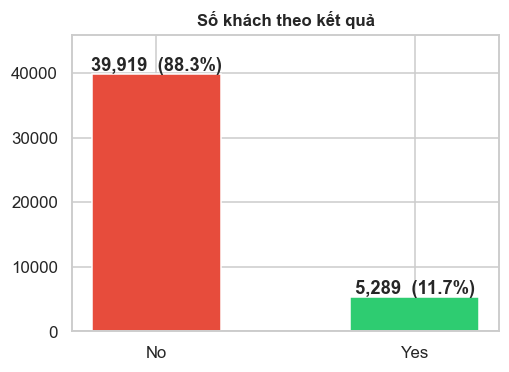

In [4]:
fig, ax = plt.subplots(figsize=(5, 3.5))
cnt = df['y'].value_counts().sort_index()
ax.bar(['No', 'Yes'], cnt.values, color=['#e74c3c', '#2ecc71'], width=0.5)
for i, v in enumerate(cnt.values): ax.text(i, v + 500, f'{v:,}  ({v / len(df):.1%})', ha='center', fontweight='bold')
ax.set_ylim(0, cnt.max() * 1.15); ax.set_title('Số khách theo kết quả'); plt.show()

**Đọc biểu đồ:** chỉ **11.7%** khách đồng ý (5,289 / 45,208), còn 88.3% từ chối.

**Ý nghĩa:**
- Dữ liệu **mất cân bằng**: mô hình đoán toàn "No" đã đúng khoảng 88% nhưng vô dụng, nên **không dùng accuracy**. Dùng PR-AUC, Precision, Recall.
- Gọi ngẫu nhiên thì 100 cuộc chỉ có khoảng 12 người đồng ý. **11.7% là mốc so sánh** cho mọi biểu đồ phía dưới.

## 4. Phân phối các biến số

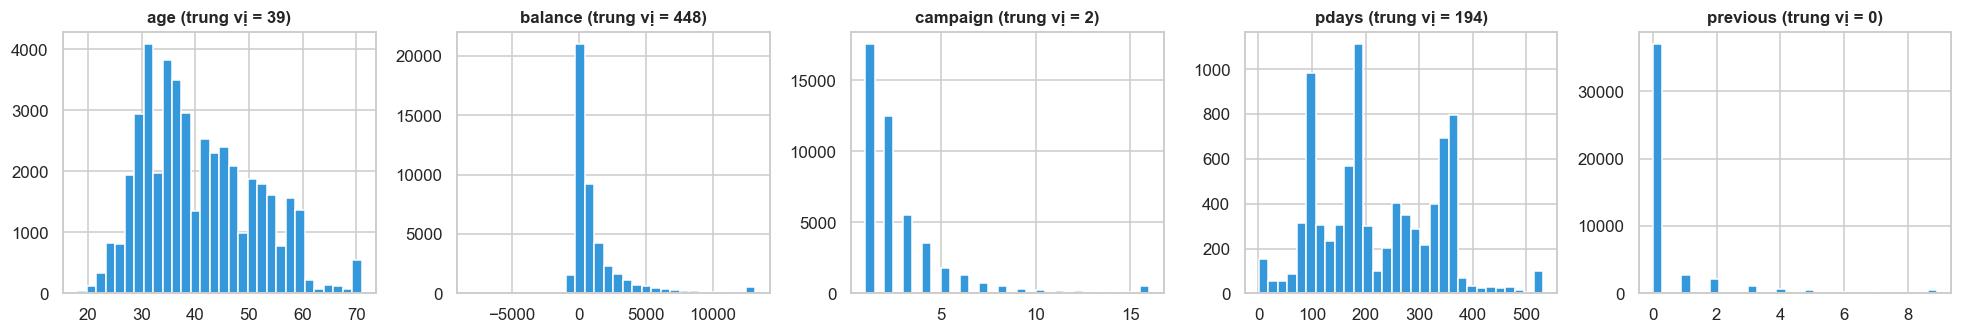

            mean    50%       max
age         40.9   39.0      95.0
balance   1362.2  448.0  102127.0
campaign     2.8    2.0      63.0
pdays       40.2   -1.0     871.0
previous     0.6    0.0     275.0

Độ lệch (skew): {'balance': 8.4, 'campaign': 4.9, 'previous': 41.8}
pdays = -1: 81.7% | balance < 0: 8.3% | campaign <= 3: 78.7%


In [5]:
num = ['age', 'balance', 'campaign', 'pdays', 'previous']
fig, axes = plt.subplots(1, 5, figsize=(18, 3.2))
for ax, c in zip(axes, num):
    x = df[c][df[c] > -1] if c == 'pdays' else df[c]                   # pdays = -1 là mã "chưa liên hệ", bỏ khi vẽ
    ax.hist(x.clip(upper=x.quantile(0.99)), bins=30, color='#3498db', edgecolor='white')   # cắt ở phân vị 99% CHỈ để vẽ
    ax.set_title(f'{c} (trung vị = {x.median():.0f})')
plt.tight_layout(); plt.show()
print(df[num].describe().round(1).T[['mean', '50%', 'max']])
print('\nĐộ lệch (skew):', df[['balance', 'campaign', 'previous']].skew().round(1).to_dict())
print(f"pdays = -1: {(df['pdays'] == -1).mean():.1%} | balance < 0: {(df['balance'] < 0).mean():.1%} | campaign <= 3: {(df['campaign'] <= 3).mean():.1%}")

**Đọc biểu đồ:**
- **`age`** khá cân đối: trung vị 39, phần lớn 33–48 tuổi; chỉ 2.6% khách trên 60 tuổi.
- **`balance`, `campaign`, `previous`** lệch phải rất mạnh (skew 8.4, 4.9, 41.8). Trung vị số dư là 448 EUR nhưng tối đa 102,127; 8.3% khách có số dư âm.
- **81.7%** khách chưa từng được liên hệ (`pdays = -1`); biểu đồ `pdays` đã bỏ nhóm này.
- 78.7% khách được gọi tối đa 3 lần.

**Ý nghĩa:** biến lệch mạnh nên khi so sánh theo nhóm cần chia **theo phân vị**, không chia khoảng đều. Với mô hình tuyến tính, nên cân nhắc biến đổi log.

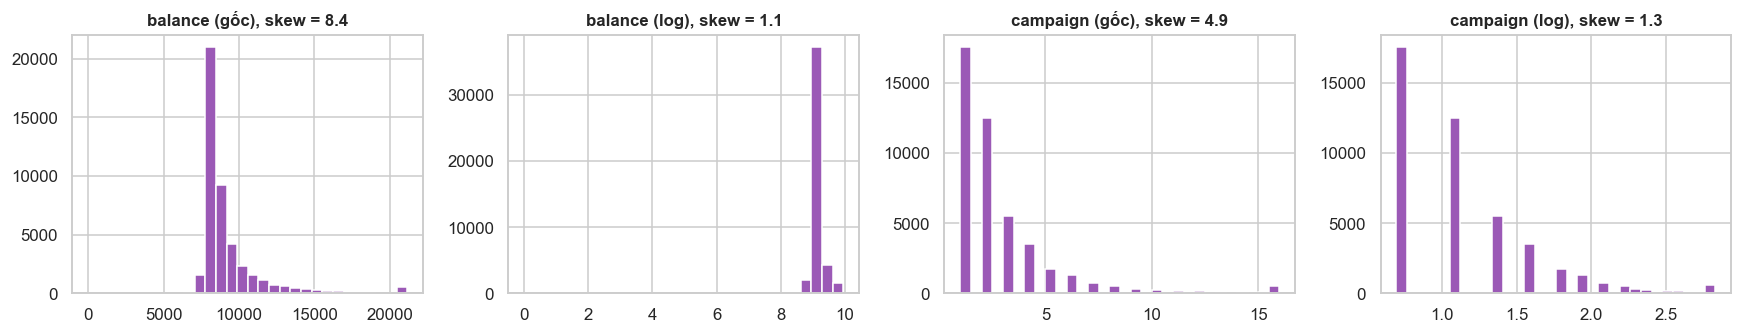

In [6]:
# So sánh trước và sau log, CHỈ ĐỂ XEM (không ghi đè dữ liệu)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
bal = df['balance'] - df['balance'].min()                                # dời để không âm
for ax, (x, name) in zip(axes, [(bal, 'balance (gốc)'), (np.log1p(bal), 'balance (log)'),
                                (df['campaign'], 'campaign (gốc)'), (np.log1p(df['campaign']), 'campaign (log)')]):
    ax.hist(x.clip(upper=x.quantile(0.99)), bins=30, color='#9b59b6', edgecolor='white'); ax.set_title(f'{name}, skew = {x.skew():.1f}')
plt.tight_layout(); plt.show()

**Đọc biểu đồ:** log làm `balance` đối xứng hơn rõ rệt và giảm độ lệch của `campaign`.

**Ý nghĩa:** biến đổi log nên đặt **trong Pipeline** cho mô hình tuyến tính (không cần cho Random Forest, XGBoost). Ở EDA chỉ dùng để quan sát.

## 5. Tỉ lệ Yes theo biến phân loại
Mỗi cột là **tỉ lệ Yes của nhóm** (không phải số khách), so với đường mức nền 11.7%. Dùng tỉ lệ vì số đếm bị các nhóm đông chi phối.

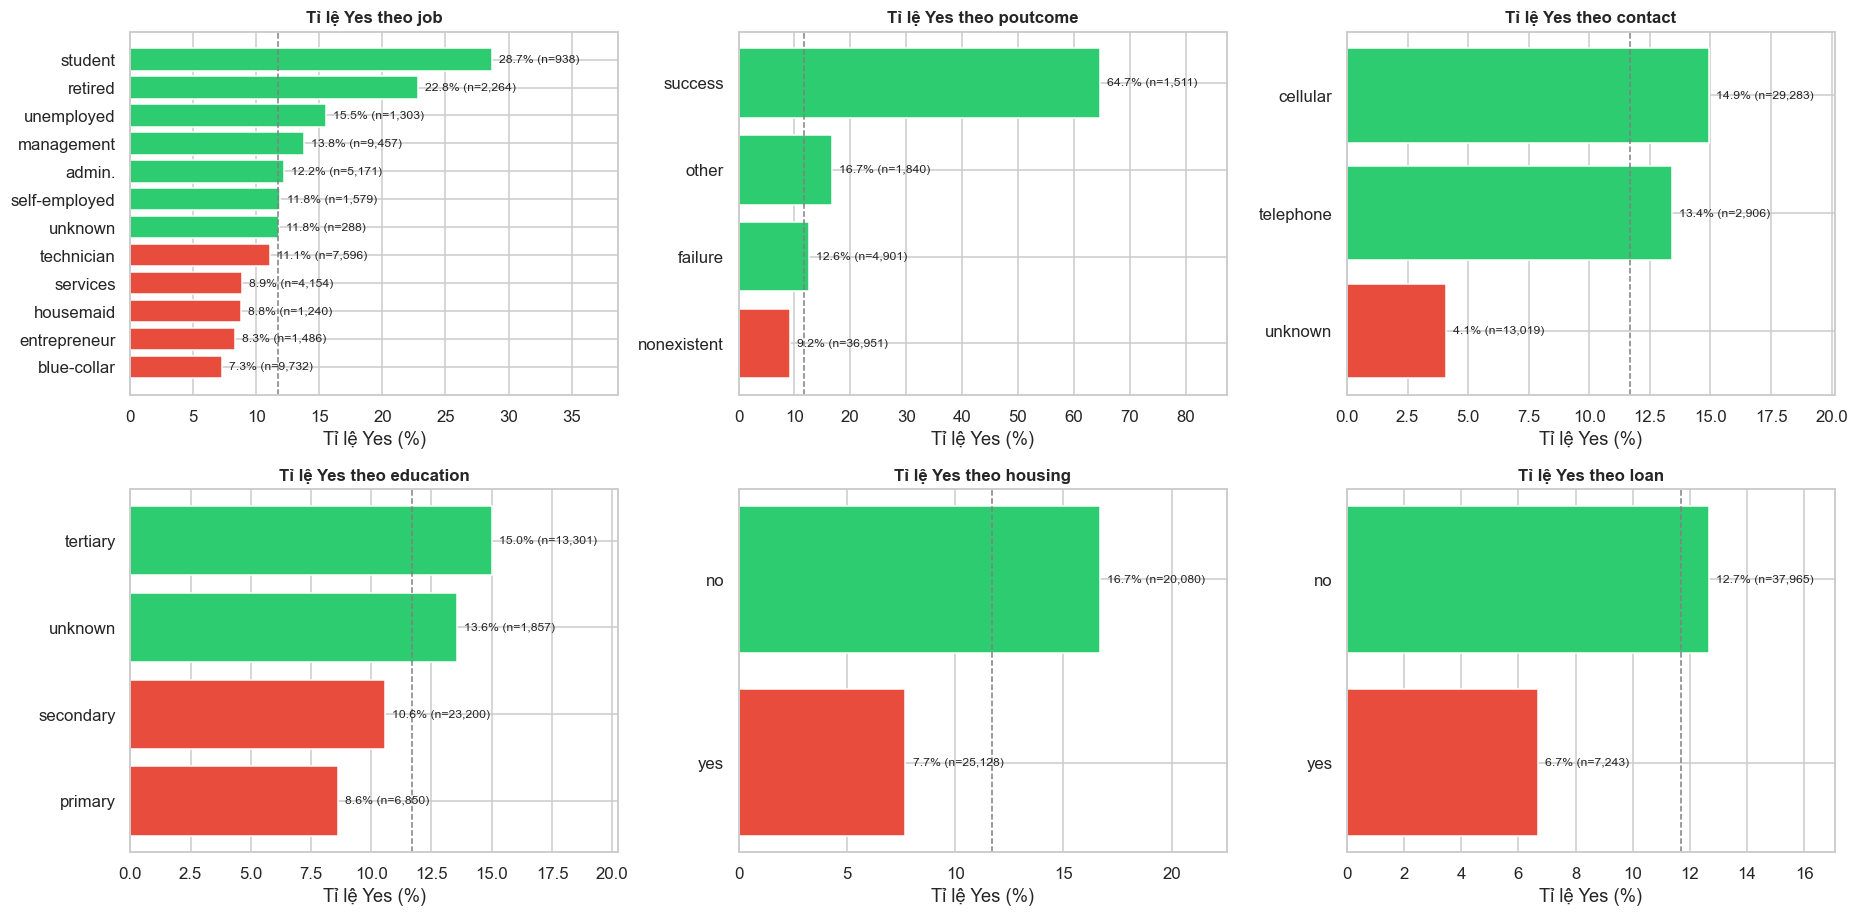

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8.5))
for ax, col in zip(axes.ravel(), ['job', 'poutcome', 'contact', 'education', 'housing', 'loan']):
    g = rate_table(col).query('n >= 30').sort_values('rate')            # bỏ nhóm quá nhỏ (vd. poutcome=unknown, n=5)
    plot_rate(ax, g, f'Tỉ lệ Yes theo {col}', horizontal=True)
plt.tight_layout(); plt.show()

**Đọc biểu đồ:**
- **`poutcome` mạnh nhất:** khách từng đồng ý chiến dịch trước (`success`) có **64.7%** Yes, gấp **5.5 lần** mức nền (chỉ 3.3% khách). `failure` 12.6% (gần nền), `nonexistent` 9.2%.
- **`job`:** `student` (28.7%) và `retired` (22.8%) cao nhất; `blue-collar` thấp nhất (7.3%).
- **`contact`:** `unknown` chỉ **4.1%** (chiếm 28.8% khách) so với 14.9% của `cellular`.
- **`housing`, `loan`:** khách **không vay** cao hơn rõ (nhà: 16.7% so với 7.7%; cá nhân: 12.7% so với 6.7%).
- **`education`:** tăng theo bậc học, từ 8.6% (primary) lên 15.0% (tertiary).

**Hành động:** ưu tiên khách từng đồng ý; hạn chế gọi khách không rõ loại liên hệ; sinh viên, người nghỉ hưu là nhóm đáng thử nhưng nhỏ.

**Cảnh báo:** một phần chênh lệch của `contact`, `housing`, `job` do giai đoạn thời gian (mục 7). Riêng `poutcome` bền ở cả ba giai đoạn.

## 6. Tỉ lệ Yes theo biến số (đã chia nhóm)

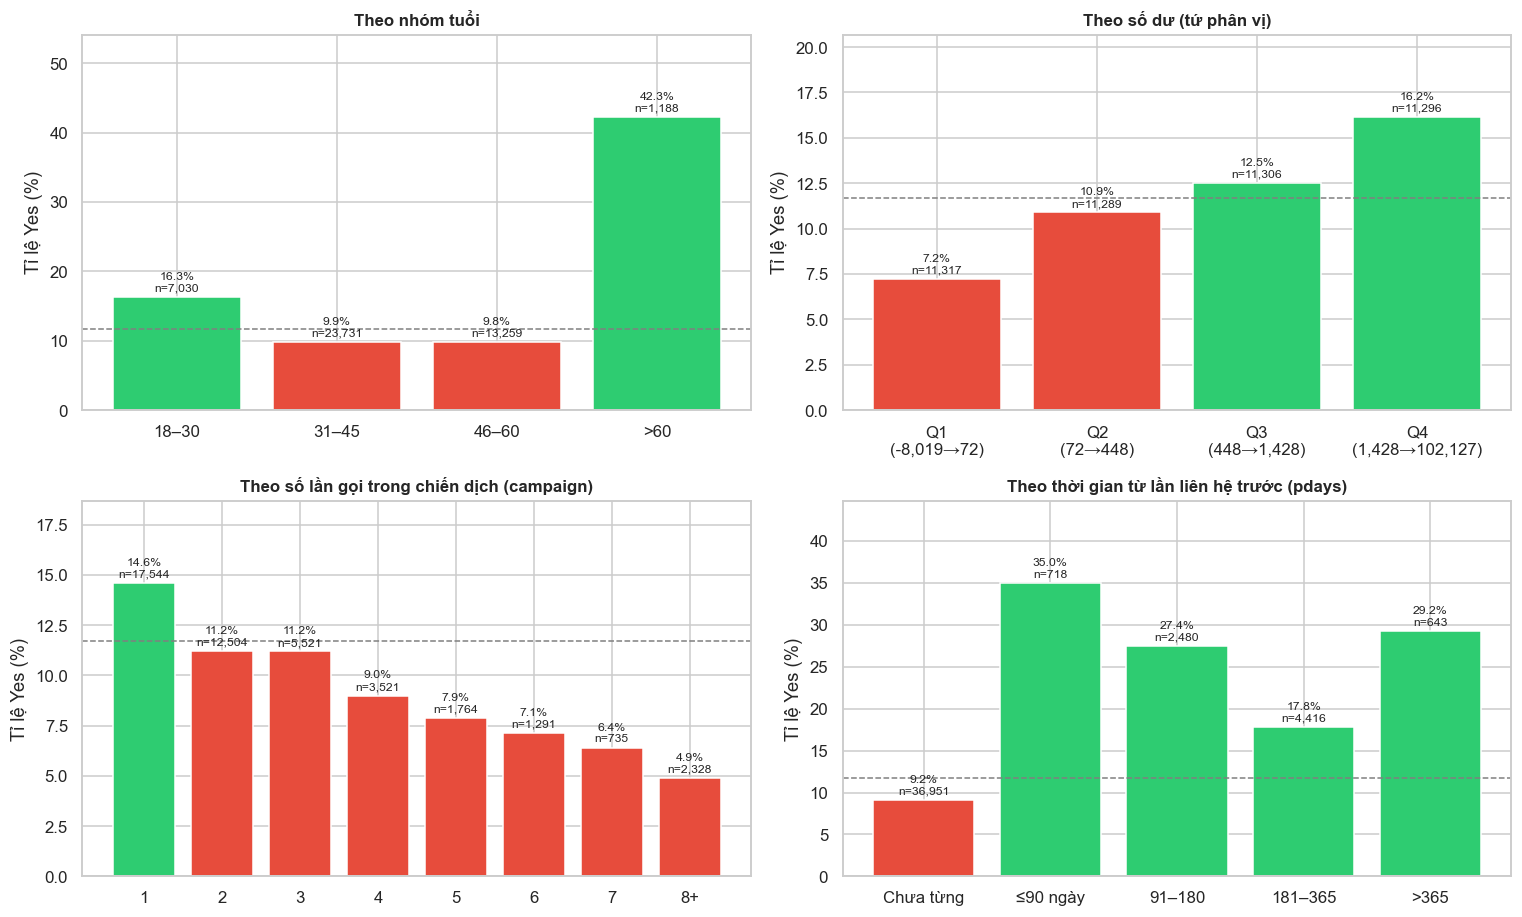

In [8]:
df['age_group'] = pd.cut(df['age'], [17, 30, 45, 60, 100], labels=['18–30', '31–45', '46–60', '>60'])
edges = df['balance'].quantile([0, .25, .5, .75, 1]).values
df['balance_q'] = pd.qcut(df['balance'], 4, labels=[f'Q{i+1}\n({edges[i]:,.0f}→{edges[i+1]:,.0f})' for i in range(4)])
df['campaign_c'] = df['campaign'].clip(upper=8).map(lambda v: '8+' if v == 8 else str(v))
df['pdays_band'] = pd.cut(df['pdays'], [-2, -1, 90, 180, 365, 900], labels=['Chưa từng', '≤90 ngày', '91–180', '181–365', '>365'])

fig, axes = plt.subplots(2, 2, figsize=(14, 8.5))
plot_rate(axes[0, 0], rate_table('age_group'), 'Theo nhóm tuổi')
plot_rate(axes[0, 1], rate_table('balance_q'), 'Theo số dư (tứ phân vị)')
plot_rate(axes[1, 0], rate_table('campaign_c').loc[[str(i) for i in range(1, 8)] + ['8+']], 'Theo số lần gọi trong chiến dịch (campaign)')
plot_rate(axes[1, 1], rate_table('pdays_band'), 'Theo thời gian từ lần liên hệ trước (pdays)')
plt.tight_layout(); plt.show()

**Đọc biểu đồ:**
- **Tuổi:** nhóm **>60** cao vọt (**42.3%**) nhưng chỉ 1,188 khách; **18–30** là 16.3%; hai nhóm đông nhất (31–60) chỉ khoảng 9.8–9.9%. Quan hệ **không đơn điệu** (cả trẻ và già đều cao hơn).
- **Số dư:** tăng đều **7.2% → 10.9% → 12.5% → 16.2%**.
- **Số lần gọi:** giảm dần từ **14.6%** (lần 1) xuống **4.9%** (8 lần trở lên).
- **`pdays`:** khách chưa từng liên hệ 9.2%; **liên hệ trong 90 ngày gần nhất 35.0%**, gấp 3 lần nền.

**Hành động:** ưu tiên khách số dư cao và vừa được liên hệ gần đây; đặt giới hạn số lần gọi (khoảng 3–4 lần).

**Cảnh báo:** `campaign` gồm cả cuộc gọi cuối và ngân hàng ngừng gọi khi khách đã đồng ý, nên một phần xu hướng giảm là **hệ quả của kết quả** (leakage nhẹ). Trước cuộc gọi đầu giá trị luôn bằng 1, nên không dùng để chọn khách.

## 7. Dữ liệu có thay đổi theo thời gian không?
File xếp theo thời gian (khoảng 5/2008 → 11/2010) nhưng **không có cột năm**, nên giai đoạn được suy ra từ thứ tự dòng.

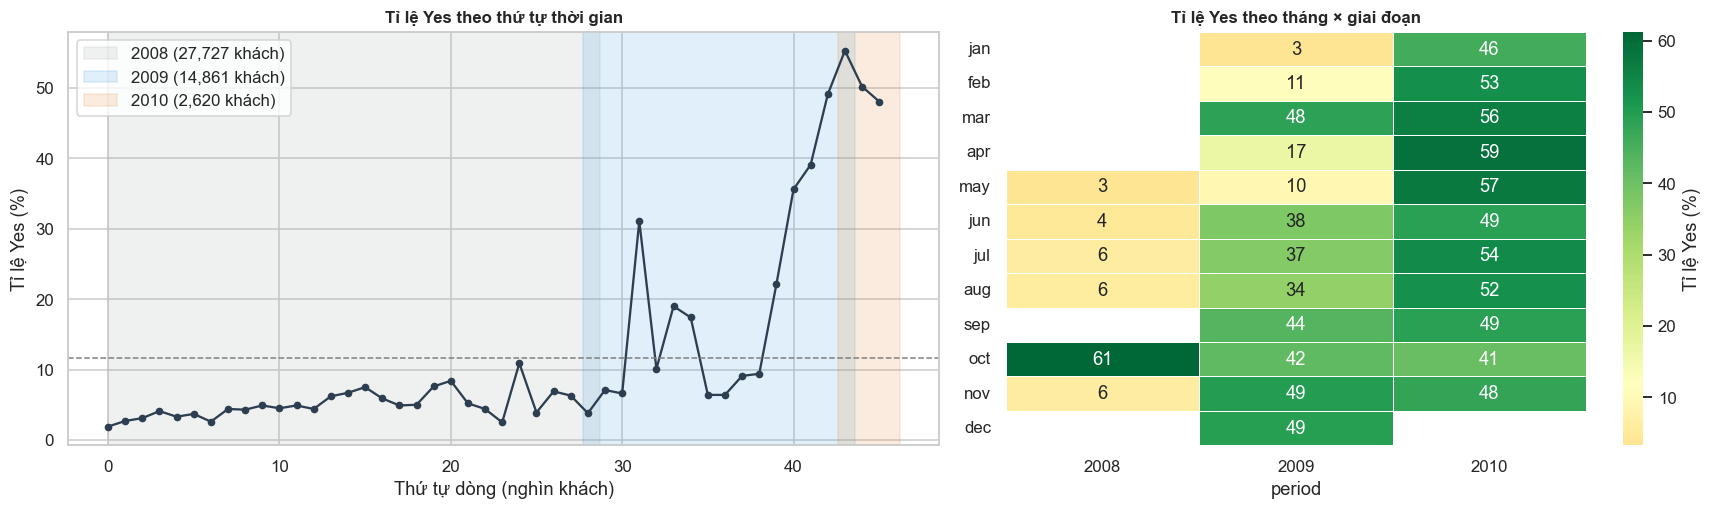

        Số_khách  Số_Yes  Tỉ_lệ
period                         
2008       27727    1401  0.051
2009       14861    2536  0.171
2010        2620    1352  0.516


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={'width_ratios': [1.2, 1]})

# Trái: tỉ lệ Yes trượt theo thứ tự dòng (mỗi điểm = 1,000 khách)
roll = df.groupby(df.index // 1000)['y'].mean() * 100
ax[0].plot(roll.index, roll.values, color='#2c3e50', marker='o', ms=4)
for p, c in {'2008': '#95a5a6', '2009': '#3498db', '2010': '#e67e22'}.items():
    rows = df.index[df['period'] == p]
    ax[0].axvspan(rows.min() / 1000, rows.max() / 1000 + 1, color=c, alpha=0.15, label=f'{p} ({len(rows):,} khách)')
ax[0].axhline(BASE, color='gray', ls='--', lw=1)
ax[0].set(title='Tỉ lệ Yes theo thứ tự thời gian', xlabel='Thứ tự dòng (nghìn khách)', ylabel='Tỉ lệ Yes (%)'); ax[0].legend()

# Phải: tỉ lệ Yes theo tháng x giai đoạn (ô trống = dưới 50 khách)
cnt = df.pivot_table(index='month', columns='period', values='y', aggfunc='size').reindex(MONTHS)
rate = (df.pivot_table(index='month', columns='period', values='y', aggfunc='mean').reindex(MONTHS) * 100).where(cnt >= 50)
sns.heatmap(rate, annot=True, fmt='.0f', cmap='RdYlGn', center=BASE, linewidths=0.5, ax=ax[1], cbar_kws={'label': 'Tỉ lệ Yes (%)'})
ax[1].set_title('Tỉ lệ Yes theo tháng × giai đoạn'); ax[1].set_ylabel(''); ax[1].grid(False)
ax[1].set_yticklabels(ax[1].get_yticklabels(), rotation=0)
plt.tight_layout(); plt.show()
print(df.groupby('period')['y'].agg(Số_khách='size', Số_Yes='sum', Tỉ_lệ='mean').round(3))

**Đọc biểu đồ: có thay đổi, và rất mạnh.**
- Tỉ lệ Yes tăng từ **5.1% (2008)** lên **17.1% (2009)** rồi **51.6% (2010)**, trong khi số cuộc gọi giảm từ **27,727** xuống **2,620**. Giai đoạn 2010 chỉ chiếm 5.8% khách nhưng có **25.6%** tổng số người đồng ý.
- Bảng nhiệt cho thấy `month` bị **trộn với năm**: cùng là tháng 5, tỉ lệ là 3% (2008), 10% (2009), 57% (2010). Tháng 3 và 9 có tỉ lệ cao (52%, 47%) chỉ vì **hầu như không có dữ liệu năm 2008**. Ô 10/2008 cao 61% nhưng chỉ có 80 khách nên không đáng tin.

**Ý nghĩa quan trọng:**
1. Mức nền 11.7% là trung bình của ba giai đoạn rất khác nhau, không phải một con số ổn định.
2. **Không kết luận "gọi vào tháng 3, 9, 10, 12 thì dễ thành công"**: đây là hiệu ứng thời gian (có thể do ngân hàng chuyển sang gọi chọn lọc), không phải đặc tính của tháng.
3. Khi xây mô hình cần **kiểm tra theo thời gian** (train quá khứ, test giai đoạn sau), nếu không điểm sẽ lạc quan.

## 8. Biến nào liên quan nhất đến kết quả?
Trái: tương quan của từng biến số với `y` (cột đỏ = `duration`, biến leakage). Phải: **ROC-AUC đơn biến** của mọi biến (0.5 = không phân biệt; biến phân loại dùng tỉ lệ Yes của nhóm làm điểm). Đây chỉ là bảng **mô tả để xếp thứ tự**, chưa phải năng lực dự đoán.

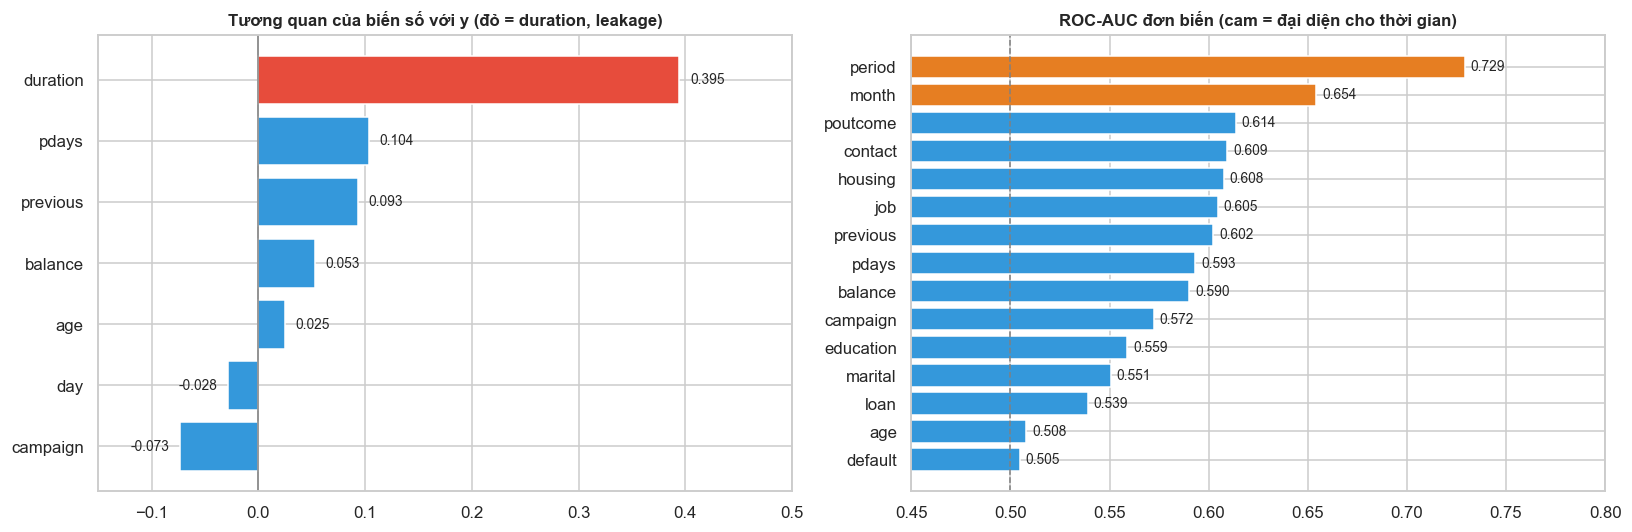

In [10]:
corr = df[['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']].corrwith(df['y']).sort_values()
auc = {}
for c in ['age', 'balance', 'campaign', 'pdays', 'previous']:
    a = roc_auc_score(df['y'], df[c]); auc[c] = max(a, 1 - a)
for c in ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'poutcome', 'month', 'period']:
    auc[c] = roc_auc_score(df['y'], df.groupby(c)['y'].transform('mean'))
auc = pd.Series(auc).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].barh(corr.index, corr.values, color=['#e74c3c' if k == 'duration' else '#3498db' for k in corr.index])
for i, v in enumerate(corr.values): ax[0].text(v + (0.01 if v >= 0 else -0.01), i, f'{v:.3f}', va='center', ha='left' if v >= 0 else 'right', fontsize=9)
ax[0].axvline(0, color='gray', lw=1); ax[0].set_xlim(-0.15, 0.5); ax[0].set_title('Tương quan của biến số với y (đỏ = duration, leakage)')
ax[1].barh(auc.index, auc.values, color=['#e67e22' if k in ('period', 'month') else '#3498db' for k in auc.index])
for i, v in enumerate(auc.values): ax[1].text(v + 0.003, i, f'{v:.3f}', va='center', fontsize=9)
ax[1].axvline(0.5, color='gray', ls='--', lw=1); ax[1].set_xlim(0.45, 0.8); ax[1].set_title('ROC-AUC đơn biến (cam = đại diện cho thời gian)')
plt.tight_layout(); plt.show()

**Đọc biểu đồ:**
- **Tương quan:** `duration` cao nhất (0.395) nhưng là biến leakage. Trong các biến dùng được: `pdays` (0.104), `previous` (0.093), `campaign` (-0.073, âm), `balance` (0.053). Tương quan tuyến tính đều yếu.
- **ROC-AUC đơn biến:** `period` (0.729) và `month` (0.654) đứng đầu nhưng chủ yếu **đại diện cho thời gian** (mục 7). Trong các biến mô tả khách và chiến dịch: `poutcome` (0.614), `contact`, `housing`, `job`, `previous` (≈0.60–0.61), `balance`, `pdays`. `age` (0.508) và `default` (0.505) gần như không phân biệt khi xét riêng vì tuổi có quan hệ không đơn điệu.

**Ý nghĩa:** **không biến đơn lẻ nào đủ mạnh**, nên cần kết hợp nhiều biến bằng mô hình, và đừng kỳ vọng độ chính xác cao.

## 9. Ý tưởng tạo feature
Các feature dưới đây dựa trên quan sát ở các mục trước và chỉ dùng thông tin **biết trước cuộc gọi**.

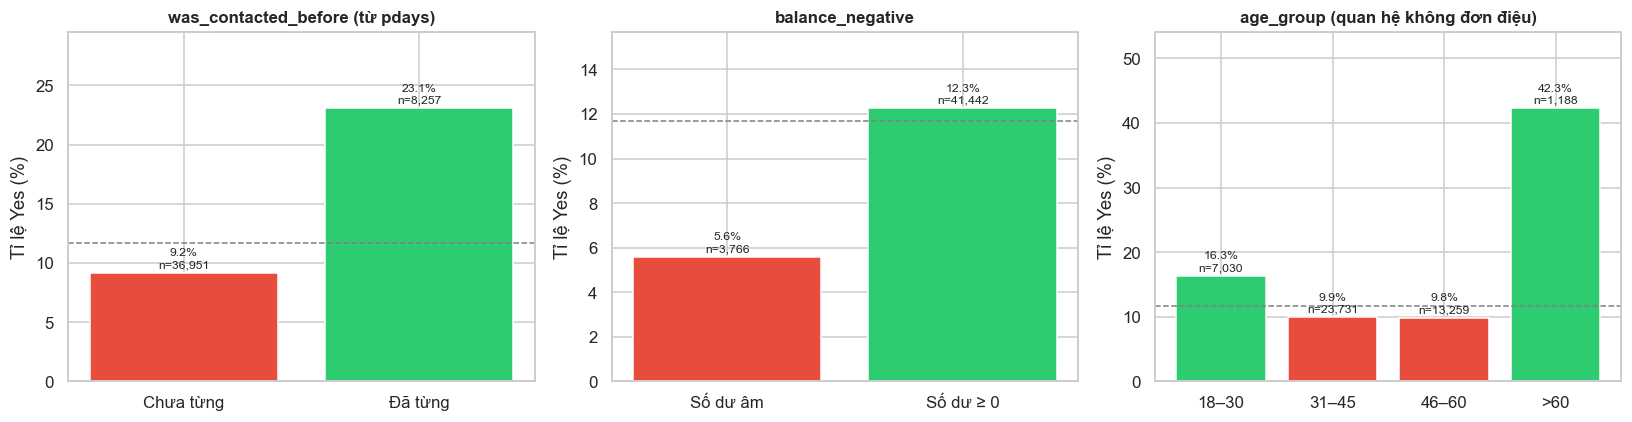

In [11]:
df['was_contacted_before'] = np.where(df['pdays'] != -1, 'Đã từng', 'Chưa từng')
df['balance_negative'] = np.where(df['balance'] < 0, 'Số dư âm', 'Số dư ≥ 0')
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plot_rate(axes[0], rate_table('was_contacted_before'), 'was_contacted_before (từ pdays)')
plot_rate(axes[1], rate_table('balance_negative'), 'balance_negative')
plot_rate(axes[2], rate_table('age_group'), 'age_group (quan hệ không đơn điệu)')
plt.tight_layout(); plt.show()

**Đọc biểu đồ và đề xuất:**

| Feature | Bằng chứng | Nhận xét |
|---|---|---|
| `was_contacted_before` | Đã từng liên hệ 23.1% so với 9.2% chưa từng | **Nên dùng**: tách rõ mã `pdays = -1` |
| `balance_negative` | Số dư âm 5.6% so với 12.3% | **Nên dùng**: cờ đơn giản, bổ sung cho `balance` |
| `age_group` | >60: 42.3%, 18–30: 16.3%, 31–60: ~9.8% | **Nên dùng** cho mô hình tuyến tính vì quan hệ không đơn điệu |
| `contact_intensity` (`campaign + previous`) | Không nên | `campaign` có leakage nhẹ nên feature kế thừa leakage |
| `month` | Chủ yếu đại diện thời gian | Cân nhắc bỏ hoặc xử lý cẩn thận |

## 10. Phân khúc ưu tiên: nên gọi ai trước?
Chia khách thành 4 nhóm chỉ bằng thông tin **biết trước cuộc gọi** (lịch sử chiến dịch và loại liên hệ).

,Số khách,Tỉ lệ Yes (%),% khách,% số Yes bắt được,Lift
tier,,,,,
A. Từng đồng ý,1511,64.7,3.3,18.5,5.5
"B. Từng liên hệ, chưa thành công",6746,13.7,14.9,17.5,1.2
C. Khách mới (có loại liên hệ),24002,11.9,53.1,54.2,1.0
D. Khách mới (contact = unknown),12949,4.0,28.6,9.8,0.3


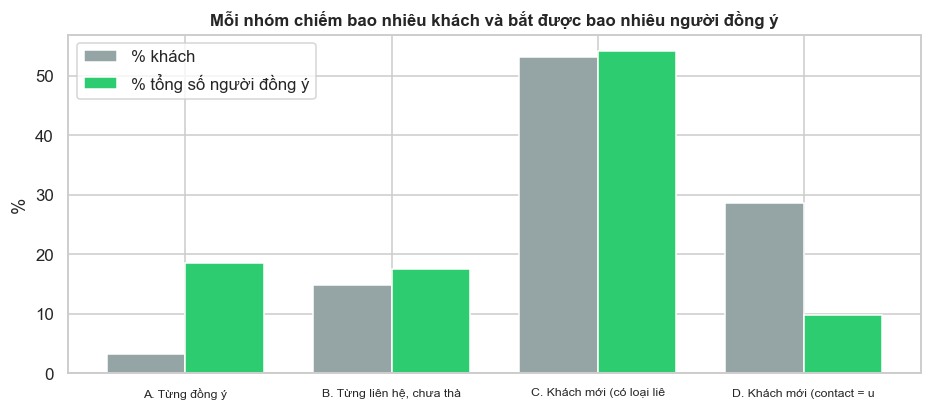

In [12]:
had_history = df['poutcome'].isin(['failure', 'other', 'success', 'unknown'])
df['tier'] = np.select(
    [df['poutcome'] == 'success', had_history, df['contact'] != 'unknown'],
    ['A. Từng đồng ý', 'B. Từng liên hệ, chưa thành công', 'C. Khách mới (có loại liên hệ)'],
    default='D. Khách mới (contact = unknown)')

g = df.groupby('tier')['y'].agg(n='size', yes='sum', rate='mean')
g['Tỉ lệ Yes (%)'] = g['rate'] * 100
g['% khách'] = g['n'] / len(df) * 100
g['% số Yes bắt được'] = g['yes'] / df['y'].sum() * 100
g['Lift'] = g['rate'] / df['y'].mean()
display(g[['n', 'Tỉ lệ Yes (%)', '% khách', '% số Yes bắt được', 'Lift']].round(1).rename(columns={'n': 'Số khách'}))

fig, ax = plt.subplots(figsize=(10, 4)); w = 0.38; x = np.arange(len(g))
ax.bar(x - w/2, g['% khách'], w, label='% khách', color='#95a5a6')
ax.bar(x + w/2, g['% số Yes bắt được'], w, label='% tổng số người đồng ý', color='#2ecc71')
ax.set_xticks(x); ax.set_xticklabels([i.split('. ')[0] + '. ' + i.split('. ')[1][:22] for i in g.index], fontsize=8)
ax.set(ylabel='%', title='Mỗi nhóm chiếm bao nhiêu khách và bắt được bao nhiêu người đồng ý'); ax.legend(); plt.show()

**Đọc kết quả:**

| Nhóm | Nhận xét |
|---|---|
| **A. Từng đồng ý** | Tỉ lệ Yes **64.7%** (gấp 5.5 lần nền). Chỉ 3.3% khách nhưng chứa **18.5%** số người đồng ý. **Ưu tiên số 1.** |
| **B. Từng liên hệ, chưa thành công** | 13.7%, gần nền. Quá khứ thất bại **không** đáng kể hơn khách mới. |
| **C. Khách mới, có loại liên hệ** | 11.9%, quanh nền; chiếm đa số khách (53.1%). |
| **D. Khách mới, `contact = unknown`** | Chỉ **4.0%** (0.34 lần nền) nhưng chiếm **28.6%** khách. Kém hiệu quả nhất. |

**Hành động đơn giản nhất:** bỏ nhóm D khỏi danh sách gọi thì giảm khoảng **28.6% chi phí** nhưng chỉ mất khoảng **9.8%** số người đồng ý. Tổ hợp tốt nhất tìm được: từng đồng ý + di động + không vay nhà → **70.4%** (940 khách).

## Phụ lục: `duration` – vì sao phải loại khỏi mô hình

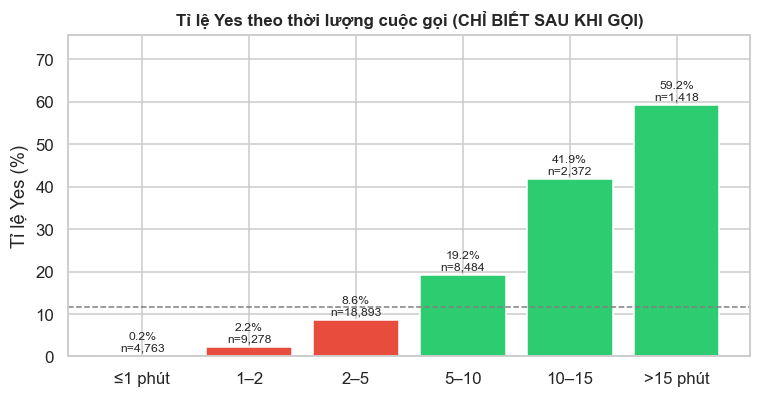

Trung vị duration (giây): {0: 164.0, 1: 426.0} | ROC-AUC của duration: 0.808


In [13]:
band = pd.cut(df['duration'], [0, 60, 120, 300, 600, 900, 5000], labels=['≤1 phút', '1–2', '2–5', '5–10', '10–15', '>15 phút'])
fig, ax = plt.subplots(figsize=(8, 3.8))
plot_rate(ax, rate_table(band), 'Tỉ lệ Yes theo thời lượng cuộc gọi (CHỈ BIẾT SAU KHI GỌI)')
plt.show()
print('Trung vị duration (giây):', df.groupby('y')['duration'].median().to_dict(), '| ROC-AUC của duration:', round(roc_auc_score(df['y'], df['duration']), 3))

**Đọc biểu đồ:** cuộc gọi càng dài, tỉ lệ Yes càng cao: **0.2%** khi ≤1 phút, **59.2%** khi trên 15 phút. Trung vị nhóm Yes là 426 giây, nhóm No là 164 giây; riêng `duration` đạt ROC-AUC **0.81**, cao hơn mọi biến khác.

**Vì sao là leakage:** thời lượng là **hệ quả** của việc khách quan tâm (khách đồng ý nói lâu, khách từ chối cúp máy sớm). Khi cần chọn khách, ngân hàng **chưa có** biến này. Đưa vào mô hình sẽ cho điểm cao giả, nên mô hình chính **loại bỏ `duration`**.

**Giá trị thực tế:** đánh giá chất lượng cuộc gọi sau đó (cuộc gọi dưới 1 phút gần như chắc chắn thất bại), không dùng để chọn khách.

## Kết luận

### Insights chính
| # | Phát hiện | Bằng chứng | Độ tin cậy |
|---|---|---|---|
| 1 | Khách từng đồng ý chiến dịch trước là nhóm tốt nhất | 64.7% so với nền 11.7%, luôn cao nhất ở cả 3 giai đoạn | **Cao** |
| 2 | Khách mới có `contact = unknown` kém hiệu quả | 4.0%, chiếm 28.6% khách | Trung bình (một phần do giai đoạn 2008) |
| 3 | Gọi lặp lại nhiều lần giảm hiệu quả | 14.6% (lần 1) → 4.9% (8+ lần) | Trung bình (`campaign` có leakage nhẹ) |
| 4 | Khách có dư nợ hoặc số dư thấp ít đồng ý | không vay nhà 16.7% so với 7.7%; số dư Q4 16.2% so với Q1 7.2% | Trung bình |
| 5 | Sinh viên, người nghỉ hưu, trên 60 tuổi có tỉ lệ cao | 28.7%, 22.8%, 42.3% | Thấp đến trung bình (nhóm nhỏ) |
| 6 | Tỉ lệ Yes thay đổi mạnh theo thời gian | 5.1% → 17.1% → 51.6% | **Cao** (rủi ro lớn nhất cho mô hình) |
| 7 | `month` chủ yếu đại diện cho thời gian | Cùng tháng 5: 3% / 10% / 57% | **Cao** |

### Hành động đề xuất cho ngân hàng
1. **Ưu tiên gọi** khách từng đồng ý chiến dịch trước và khách vừa được liên hệ gần đây (≤90 ngày).
2. **Hạn chế gọi** khách mới không rõ loại liên hệ; **giới hạn 3–4 lần gọi** mỗi khách.
3. **Thử nghiệm riêng** nhóm sinh viên, người nghỉ hưu, trên 60 tuổi (nhóm nhỏ nên cần đo lại).
4. Dùng `duration` để đánh giá chất lượng cuộc gọi, **không** để chọn khách.

### Hàm ý cho bước xây mô hình (làm trên tập train, trong Pipeline)
- **Chia train/test một lần**, rồi mới điền thiếu, scale, one-hot, chọn biến: mọi bước học thống kê chỉ fit trên train.
- Loại `duration` và `day`; cân nhắc **bỏ `campaign`** (leakage nhẹ) và **bỏ hoặc xử lý `month`** (đại diện thời gian).
- Giữ `unknown` của `contact` làm **nhóm riêng**; thêm `was_contacted_before`, `balance_negative`, `age_group`.
- **Kiểm tra theo thời gian** ngoài chia ngẫu nhiên; dùng **PR-AUC, Precision, Recall**, chọn ngưỡng bằng out-of-fold trên train; **không** tinh chỉnh bằng test.